# Tactic model comparison

Compares the tactic models on the 2026-11-16 training clips (82 clips from four matches; Spirit #5, with an uncertain boundary, is excluded). Each match is held out in turn and predicted by models trained on the other three. NaVi-Falcons and Vitality-Falcons (the test matches) are never read here, and no test score is shown.

1. Select the project's **.venv** Python kernel, then run the cells from top to bottom.
2. The first cell names the saved run folders. The notebook only reads them: it trains nothing and writes nothing.
3. A missing run folder leaves out the rows or tables that need it, with a note.

**Main section: one version per model, all under the TCN's epoch rule.** Each held-out match is scored at the epoch that is best on the mean validation curve of the *other* matches (averaged over seeds, earliest on ties), the same epoch for every seed. This rule is **slightly optimistic**: the other matches' models, which choose the epoch, were trained on the scored match. The nested numbers in the appendix keep the scored match out completely and are the stricter estimate.

Two numbers per model, as the TCN reports them: **mean over seeds** (each seed's macro-F1 averaged equally over the four matches, then over seeds 0-2) and **seed ensemble** (each clip's class probabilities averaged over the three seeds, then scored once over all 82 clips). Per class, site against split-or-direct and the confusion matrix use the seed ensemble.

In [1]:
from pathlib import Path

# Main section: all under the TCN's epoch rule (cross-validation only).
OTHER_FOLDS_RUN = "runs/tactic-temporal-other-folds-20261119"  # baseline, temporal average pooling (and the first GRU)
# The three GRU versions, each fixed before its score was seen. The main comparison shows the
# one with the highest macro-F1 (mean over seeds); appendix A5 lists all three.
GRU_RUNS = {
    "first": OTHER_FOLDS_RUN,
    "smaller": "runs/tactic-gru-small-other-folds-20261119",
    "pooled": "runs/tactic-gru-pooled-other-folds-20261119",
}
TCN_RUN = "runs/tactic-tcn-repro-20261119"  # TCN on detector features
TCN_CLIPDATA_RUN = "runs/tactic-tcn-clipdata-final"  # TCN and time-blind control on the shared clip data

# Appendix: nested epoch choice.
IMAGE_RUN = "runs/tactic-temporal-20261116"
RANDOM_THIRDS_RUN = "runs/tactic-temporal-random-thirds-20261117"
POSITION_RUN = "runs/tactic-positions-20261117"
POSITION_NO_BOMB_RUN = "runs/tactic-positions-no-bomb-20261117"

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "stratscout").is_dir() and (p / "AGENTS.md").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the CV-DL repository or its notebooks folder.")
runs = {
    name: (ROOT / path).resolve()
    for name, path in {
        "other_folds": OTHER_FOLDS_RUN,
        **{f"gru_{version}": path for version, path in GRU_RUNS.items()},
        "tcn": TCN_RUN,
        "tcn_clipdata": TCN_CLIPDATA_RUN,
        "images": IMAGE_RUN,
        "random_thirds": RANDOM_THIRDS_RUN,
        "positions": POSITION_RUN,
        "positions_no_bomb": POSITION_NO_BOMB_RUN,
    }.items()
}
for name, folder in runs.items():
    marker = "summary.json" if not name.startswith("tcn") else "report.json"
    print(f"{'found  ' if (folder / marker).is_file() else 'MISSING'}  {name:<18} {folder}")

found    other_folds        C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-temporal-other-folds-20261119
found    gru_first          C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-temporal-other-folds-20261119
found    gru_smaller        C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-gru-small-other-folds-20261119
found    gru_pooled         C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-gru-pooled-other-folds-20261119
found    tcn                C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-tcn-repro-20261119
found    tcn_clipdata       C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-tcn-clipdata-final
found    images             C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-temporal-20261116
found    random_thirds      C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-temporal-random-thirds-20261117
found    positions          C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-positions-20261117
found    positions_no_bomb  C:\Users\USER\Documents\GitHub\CV-DL\runs\tactic-

In [2]:
import csv
import json

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

CLASSES = ["A_DIRECT", "B_DIRECT", "A_SPLIT", "B_SPLIT", "RETAKE"]
SITE = {"A_DIRECT": "A", "A_SPLIT": "A", "B_DIRECT": "B", "B_SPLIT": "B", "RETAKE": "RETAKE"}
MATCH_NAMES = {
    "spirit-falcons-mirage-cologne-major": "Spirit vs Falcons",
    "furia-falcons-mirage-cologne-major-2026": "Furia vs Falcons",
    "mouz-betboom-mirage-iem-bejing-2026": "MOUZ vs BetBoom",
    "aurora-vitality-mirage-esl-pro-league-season-24": "Aurora vs Vitality",
}


FONT = "font-family: 'Segoe UI', Arial, sans-serif; font-size: 13px;"


MARKERS = ("planned", "not run", "-")  # Allowed in a number column; shown as written.


def is_number_column(column):
    """Numbers, or text that reads as a number such as '0.584 +/- 0.016' or '0 of 20'."""
    if pd.api.types.is_numeric_dtype(column):
        return True
    values = [v for v in column if not (isinstance(v, str) and v.startswith(MARKERS))]
    return bool(values) and all(
        isinstance(v, (int, float, np.number)) or isinstance(v, str) and (v[:1].isdigit() or v[:1] == "-")
        for v in values
    )


def number_format(decimals):
    def fmt(value):
        if isinstance(value, (bool, np.bool_)) or isinstance(value, str):
            return str(value)
        if isinstance(value, (int, np.integer)):
            return f"{value:d}"
        return f"{value:.{decimals}f}"
    return fmt


def show_table(df, decimals=3):
    """Show one table: text columns left, number columns right (headers too), scores to
    three decimals, counts as whole numbers, no index, one font for headers and cells."""
    numbers = [c for c in df.columns if is_number_column(df[c])]
    text = [c for c in df.columns if c not in numbers]
    formats = {c: number_format(decimals) for c in numbers}
    styles = [
        {"selector": "th", "props": FONT + " font-weight: 600; padding: 4px 10px; border-bottom: 1px solid #999;"},
        {"selector": "td", "props": FONT + " padding: 4px 10px;"},
    ]
    for i, column in enumerate(df.columns):
        side = "right" if column in numbers else "left"
        styles.append({"selector": f"th.col_heading.col{i}", "props": f"text-align: {side};"})
    styler = df.style.hide(axis="index").format(formats).set_table_styles(styles)
    if text:
        styler = styler.set_properties(subset=text, **{"text-align": "left"})
    if numbers:
        styler = styler.set_properties(subset=numbers, **{"text-align": "right"})
    display(styler)


def match_of(clip_id):
    return clip_id.split(".")[0]


def ensemble(rows):
    """Seed ensemble pooled over clips: mean probability over seeds per clip, then metrics."""
    by_clip = {}
    for row in rows:
        clip = by_clip.setdefault(row["clip_id"], {"truth": row["truth"], "probs": []})
        clip["probs"].append([float(row[f"p_{c}"]) for c in CLASSES])
    truth = np.array([CLASSES.index(c["truth"]) for c in by_clip.values()])
    predicted = np.array([np.mean(c["probs"], axis=0).argmax() for c in by_clip.values()])
    matrix = np.zeros((5, 5), int)
    np.add.at(matrix, (truth, predicted), 1)
    f1 = {}
    for i, label in enumerate(CLASSES):
        denominator = matrix[i].sum() + matrix[:, i].sum()
        f1[label] = 2 * matrix[i, i] / denominator if denominator else 0.0
    return {
        "macro_f1": float(np.mean(list(f1.values()))),
        "accuracy": float(np.trace(matrix) / matrix.sum()),
        "per_class": f1,
        "confusion": matrix,
        "clips": sorted(by_clip),
    }


def read_resnet(folder, model):
    """One model folder from tactic-temporal: scores per (match, seed), ensemble, shuffled check."""
    model_dir = folder / model
    if not (model_dir / "summary.json").is_file():
        return None
    summary = json.loads((model_dir / "summary.json").read_text(encoding="utf-8"))
    pairs, clips = {}, {}
    for path in sorted(model_dir.glob("fold-[0-9].json")):
        fold = json.loads(path.read_text(encoding="utf-8"))
        match = match_of(fold["validation_clip_ids"][0])
        clips[match] = sorted(fold["validation_clip_ids"])
        for run in fold["runs"]:
            pairs[(match, run["seed"])] = run["metrics"]["macro_f1"]
            for label in CLASSES:
                pairs.setdefault(("class", label, match, run["seed"]), run["metrics"]["per_class"][label]["f1"])
    with (model_dir / "predictions.csv").open(encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    shuffled = model_dir / "shuffled-labels.json"
    seeds = sorted({s for (m, s) in [k for k in pairs if len(k) == 2]})
    per_seed = [np.mean([pairs[(m, s)] for m in clips]) for s in seeds]
    return {
        "mode": summary["epoch_mode"],
        "seed_mean": float(np.mean(per_seed)),
        "seed_sd": float(np.std(per_seed)),
        "per_match": {m: float(np.mean([pairs[(m, s)] for s in seeds])) for m in clips},
        "pairs": {k: v for k, v in pairs.items() if len(k) == 2},
        "class_f1": {
            label: float(np.mean([v for k, v in pairs.items() if len(k) == 4 and k[1] == label]))
            for label in CLASSES
        },
        "ensemble": ensemble(rows),
        "clips": clips,
        "shuffled": json.loads(shuffled.read_text(encoding="utf-8")) if shuffled.is_file() else None,
    }


def read_tcn(folder, kind):
    """Cross-validation of one train-tactics model. Test results in the folder are never read."""
    path = folder / "report.json"
    if not path.is_file():
        return None
    report = json.loads(path.read_text(encoding="utf-8"))
    if kind not in report["models"]:
        return None
    cv = report["models"][kind]["cv"]
    per_seed = []
    for seed in report["config"]["seeds"]:
        scores = []
        for match, epoch in cv["cross_fold_epochs"].items():
            history = next(
                r["history"] for r in report["models"][kind]["cv_runs"] if r["held_out"] == match and r["seed"] == seed
            )
            scores.append(dict(history)[epoch])
        per_seed.append(np.mean(scores))
    with (folder / "cv_predictions.csv").open(encoding="utf-8") as stream:
        rows = [{**r, "truth": r["true"]} for r in csv.DictReader(stream) if r["model"] == kind]
    clips = {}
    for row in rows:
        clips.setdefault(row["match"], []).append(row["clip_id"])
    pooled = cv["pooled"]["ensemble"]  # Saved from unrounded probabilities.
    return {
        "mode": "other-folds (TCN)",
        "seed_mean": cv["cross_fold_macro_f1"],
        "seed_sd": float(np.std(per_seed)),
        "per_match": cv["per_fold_macro_f1"],
        "ensemble": {
            "macro_f1": pooled["macro_f1"],
            "accuracy": pooled["accuracy"],
            "per_class": {c: pooled["per_class"][c]["f1"] for c in CLASSES},
            "confusion": np.array(pooled["confusion"]),
            "clips": sorted(r["clip_id"] for r in rows),
        },
        "clips": {m: sorted(v) for m, v in clips.items()},
        "shuffled": None,
        "excluded": report["excluded_uncertain"],
    }


def gru_settings(folder):
    """The saved GRU settings; runs from before an option existed used the old value."""
    config = json.loads((folder / "gru" / "config.json").read_text(encoding="utf-8"))
    t = config["temporal"]
    settings = {
        "projection": t["projection"],
        "hidden": t["hidden"],
        "dropout": t.get("dropout", 0.0),
        "readout": t.get("readout", "last"),
    }
    readout = "mean+max over all frames" if settings["readout"] == "mean-max" else "last state"
    text = f"{settings['projection']}/{settings['hidden']}, dropout {settings['dropout']:g}, {readout}"
    return text, config["trainable_parameters"]


gru_versions = {}
for version in GRU_RUNS:
    folder = runs[f"gru_{version}"]
    result = read_resnet(folder, "gru")
    if result is None:
        print(f"Left out (run not found): GRU version '{version}'")
        continue
    settings, weights = gru_settings(folder)
    gru_versions[version] = {"result": result, "settings": settings, "weights": weights}
best_gru = max(gru_versions, key=lambda v: gru_versions[v]["result"]["seed_mean"]) if gru_versions else None
GRU_LABEL = f"GRU ({gru_versions[best_gru]['settings']})" if best_gru else "GRU"

main_spec = [
    ("Baseline (mean pooling)", "ResNet-18 images", lambda: read_resnet(runs["other_folds"], "mean")),
    ("Temporal average pooling (3 segments) + linear classifier", "ResNet-18 images", lambda: read_resnet(runs["other_folds"], "thirds")),
    (GRU_LABEL, "ResNet-18 images", lambda: gru_versions[best_gru]["result"] if best_gru else None),
    ("TCN", "detector features", lambda: read_tcn(runs["tcn"], "tcn")),
    ("TCN (clip data)", "Clip data (detector channels + ResNet)", lambda: read_tcn(runs["tcn_clipdata"], "tcn")),
    ("Time-blind control (clip data)", "Clip data (detector channels + ResNet)", lambda: read_tcn(runs["tcn_clipdata"], "control")),
]
SHORT = {
    "Baseline (mean pooling)": "Baseline",
    "Temporal average pooling (3 segments) + linear classifier": "Temporal avg. pooling (3 seg.)",
    GRU_LABEL: "GRU",
    "TCN": "TCN",
    "TCN (clip data)": "TCN (clip data)",
    "Time-blind control (clip data)": "Time-blind control (clip data)",
}
main, main_inputs = {}, {}
for label, inputs, load in main_spec:
    result = load()
    if result is None:
        print(f"Left out (run not found): {label}")
        continue
    main[label], main_inputs[label] = result, inputs

reference = next(iter(main.values()))["clips"] if main else None
for label, result in main.items():
    if result["clips"] != reference:
        raise ValueError(f"{label} does not use the same clips and validation matches as the other rows.")
if main:
    print(f"All {len(main)} main rows use the same {sum(map(len, reference.values()))} clips and four validation matches.")

All 6 main rows use the same 82 clips and four validation matches.


## Main comparison (TCN's epoch rule)

### Overall

Bars: mean over seeds, with the seed standard deviation. Diamonds: seed ensemble. The last two rows are models on the shared clip data, a different input: the TCN and its time-blind control, trained on detector channels per map region plus compressed ResNet numbers. Gaps are a rough guide, not a significance test: the seeds rerun the same four matches.

Model,Input,"Macro-F1, mean over seeds",Seed ensemble macro-F1,Seed ensemble accuracy
Baseline (mean pooling),ResNet-18 images,0.584 +/- 0.016,0.627,0.646
Temporal average pooling (3 segments) + linear classifier,ResNet-18 images,0.650 +/- 0.013,0.691,0.707
"GRU (8/16, dropout 0.3, mean+max over all frames)",ResNet-18 images,0.681 +/- 0.049,0.736,0.756
TCN,detector features,0.679 +/- 0.016,0.693,0.707
TCN (clip data),Clip data (detector channels + ResNet),0.836 +/- 0.025,0.833,0.841
Time-blind control (clip data),Clip data (detector channels + ResNet),0.823 +/- 0.027,0.845,0.866


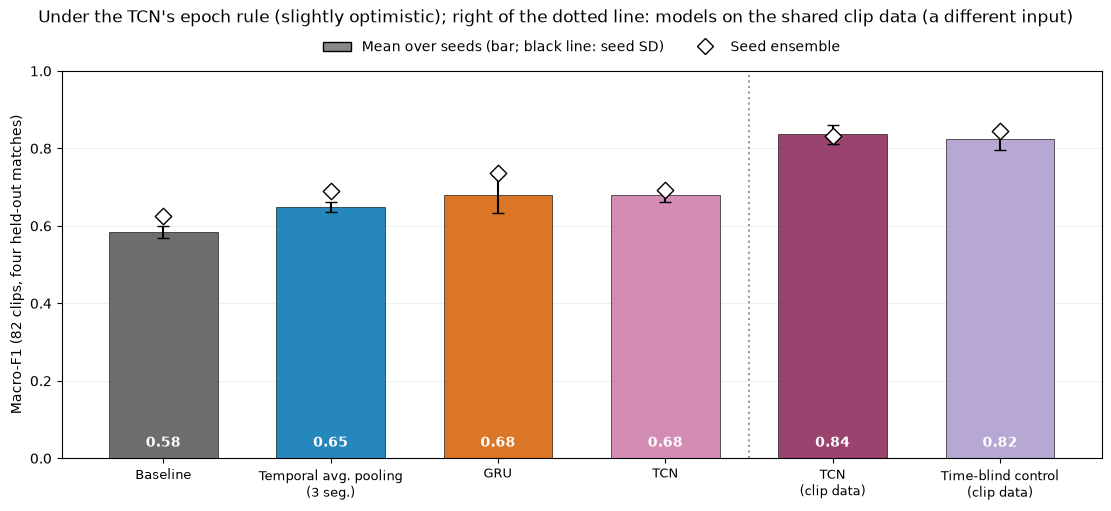

In [3]:
labels = list(main)
colours = ["#555555", "#0072B2", "#D55E00", "#CC79A7", "#882255", "#AA99CC"][: len(labels)]
show_table(
    pd.DataFrame(
        [
            [label, main_inputs[label], f"{r['seed_mean']:.3f} +/- {r['seed_sd']:.3f}", r["ensemble"]["macro_f1"], r["ensemble"]["accuracy"]]
            for label, r in main.items()
        ],
        columns=["Model", "Input", "Macro-F1, mean over seeds", "Seed ensemble macro-F1", "Seed ensemble accuracy"],
    )
)
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
for x, (label, colour) in enumerate(zip(labels, colours)):
    r = main[label]
    ax.bar(x, r["seed_mean"], 0.65, color=colour, alpha=0.85, edgecolor="black", linewidth=0.5)
    ax.errorbar(x, r["seed_mean"], yerr=r["seed_sd"], color="black", capsize=4)
    ax.scatter(x, r["ensemble"]["macro_f1"], marker="D", color="white", edgecolor="black", s=70, zorder=4)
    ax.annotate(f"{r['seed_mean']:.2f}", (x, 0.03), ha="center", color="white", weight="bold")
ax.axvline(3.5, color="#999999", linestyle=":")
ax.set_xticks(range(len(labels)), [SHORT[l].replace(" (", "\n(").replace(", clip", "\nclip") for l in labels], fontsize=9)
ax.set_ylim(0, 1)
ax.set_ylabel("Macro-F1 (82 clips, four held-out matches)")
fig.suptitle("Under the TCN's epoch rule (slightly optimistic); right of the dotted line: models on the shared clip data (a different input)")
ax.legend(
    handles=[
        Patch(facecolor="#888888", edgecolor="black", label="Mean over seeds (bar; black line: seed SD)"),
        Line2D([], [], marker="D", linestyle="none", markerfacecolor="white", markeredgecolor="black", markersize=8, label="Seed ensemble"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

### Per validation match

Macro-F1, mean over seeds.

In [4]:
matches = list(MATCH_NAMES)
show_table(
    pd.DataFrame(
        [[SHORT[label]] + [r["per_match"][m] for m in matches] for label, r in main.items()],
        columns=["Model"] + [MATCH_NAMES[m] for m in matches],
    )
)

Model,Spirit vs Falcons,Furia vs Falcons,MOUZ vs BetBoom,Aurora vs Vitality
Baseline,0.531,0.655,0.583,0.566
Temporal avg. pooling (3 seg.),0.563,0.709,0.740,0.587
GRU,0.791,0.654,0.711,0.567
TCN,0.620,0.871,0.674,0.550
TCN (clip data),0.700,0.906,0.783,0.955
Time-blind control (clip data),0.720,0.810,0.885,0.877


### Per class

F1 per class from the seed ensemble, pooled over the 82 clips; the same method for every row. *Time-blind control (clip data)* is the TCN's time-blind control trained on the shared clip data.

Class,Clips,Baseline,Temporal avg. pooling (3 seg.),GRU,TCN,TCN (clip data),Time-blind control (clip data)
A_DIRECT,15,0.571,0.625,0.686,0.710,0.759,0.788
B_DIRECT,24,0.711,0.711,0.833,0.727,0.913,0.979
A_SPLIT,14,0.462,0.667,0.615,0.714,0.788,0.692
B_SPLIT,9,0.600,0.600,0.706,0.545,0.842,0.842
RETAKE,20,0.789,0.850,0.842,0.769,0.865,0.923


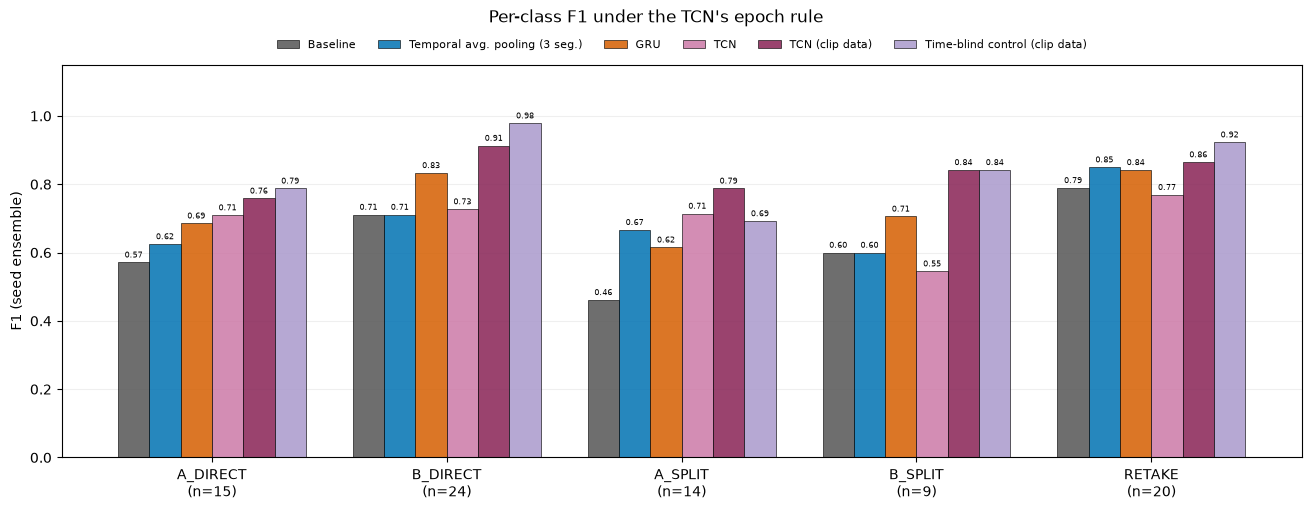

In [5]:
counts = next(iter(main.values()))["ensemble"]["confusion"].sum(axis=1)
show_table(
    pd.DataFrame(
        [[c, int(counts[i])] + [main[l]["ensemble"]["per_class"][c] for l in labels] for i, c in enumerate(CLASSES)],
        columns=["Class", "Clips"] + [SHORT[l] for l in labels],
    )
)
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
width = 0.8 / len(labels)
x = np.arange(len(CLASSES))
for k, (label, colour) in enumerate(zip(labels, colours)):
    values = [main[label]["ensemble"]["per_class"][c] for c in CLASSES]
    bars = ax.bar(x - 0.4 + width * (k + 0.5), values, width, color=colour, alpha=0.85, edgecolor="black", linewidth=0.5, label=SHORT[label])
    ax.bar_label(bars, labels=["" if v == 0 else f"{v:.2f}" for v in values], padding=2, fontsize=6)
    for bar, v in zip(bars, values):
        if v == 0:  # A zero-height bar is invisible; mark it in the bar's colour.
            ax.annotate("0", (bar.get_x() + bar.get_width() / 2, 0), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=8, weight="bold", color=colour)
ax.set_xticks(x, [f"{c}\n(n={int(counts[i])})" for i, c in enumerate(CLASSES)])
ax.set_ylim(0, 1.15)
ax.set_ylabel("F1 (seed ensemble)")
fig.suptitle("Per-class F1 under the TCN's epoch rule")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=len(labels), fontsize=8, frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

### Site against split-or-direct

Each prediction split into two steps, from the seed ensemble: **site right** puts a clip in the right group (A, B or RETAKE); **split or direct right** is, for A and B clips whose site was right, whether the split/direct choice was right too.

Model,Site right,"Split/direct right, given site","A/B clips, site right"
Baseline,0.902,0.644,59
Temporal avg. pooling (3 seg.),0.915,0.707,58
GRU,0.927,0.767,60
TCN,0.866,0.768,56
TCN (clip data),0.927,0.883,60
Time-blind control (clip data),0.939,0.898,59


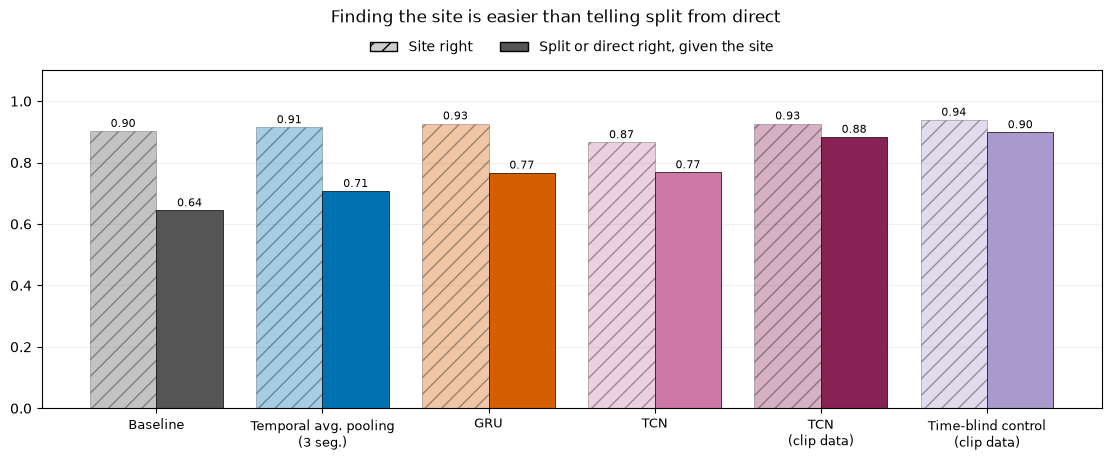

In [6]:
def site_split(matrix):
    same = [(i, j) for i, t in enumerate(CLASSES) for j, p in enumerate(CLASSES) if SITE[t] == SITE[p]]
    attack = [(i, j) for i, j in same if SITE[CLASSES[i]] != "RETAKE"]
    given = sum(matrix[i][j] for i, j in attack)
    exact = sum(matrix[i][i] for i in range(5) if SITE[CLASSES[i]] != "RETAKE")
    return sum(matrix[i][j] for i, j in same) / matrix.sum(), exact / given, int(given)


breakdown = {label: site_split(r["ensemble"]["confusion"]) for label, r in main.items()}
show_table(
    pd.DataFrame(
        [[SHORT[label], s, d, n] for label, (s, d, n) in breakdown.items()],
        columns=["Model", "Site right", "Split/direct right, given site", "A/B clips, site right"],
    )
)
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
x = np.arange(len(labels))
for xi, l, colour in zip(x, labels, colours):
    ax.bar(xi - 0.2, breakdown[l][0], 0.4, color=colour, alpha=0.35, hatch="//", edgecolor="black", linewidth=0.5)
    ax.bar(xi + 0.2, breakdown[l][1], 0.4, color=colour, edgecolor="black", linewidth=0.5)
for xi, l in zip(x, labels):
    ax.annotate(f"{breakdown[l][0]:.2f}", (xi - 0.2, breakdown[l][0]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.annotate(f"{breakdown[l][1]:.2f}", (xi + 0.2, breakdown[l][1]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(x, [SHORT[l].replace(" (", "\n(").replace(", clip", "\nclip") for l in labels], fontsize=9)
ax.set_ylim(0, 1.1)
fig.suptitle("Finding the site is easier than telling split from direct")
ax.legend(
    handles=[
        Patch(facecolor="#cccccc", hatch="//", edgecolor="black", label="Site right"),
        Patch(facecolor="#555555", edgecolor="black", label="Split or direct right, given the site"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

### Confusion matrix of the best model

The row with the highest macro-F1 (mean over seeds); seed ensemble, all 82 clips. Rows are true classes, columns predictions.

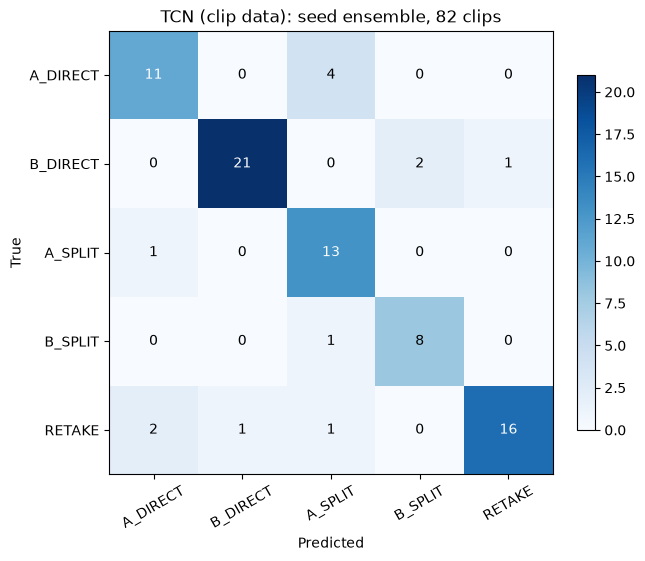

In [7]:
best = max(main, key=lambda l: main[l]["seed_mean"])
matrix = main[best]["ensemble"]["confusion"]
fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
image = ax.imshow(matrix, cmap="Blues")
for i in range(5):
    for j in range(5):
        ax.text(j, i, matrix[i, j], ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ax.set_xticks(range(5), CLASSES, rotation=30)
ax.set_yticks(range(5), CLASSES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"{best}: seed ensemble, 82 clips")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

## Shuffled-label check

Each ResNet run refitted its whole protocol 20 times on labels shuffled within each match and scored against those shuffled labels. A sound procedure lands near chance, far below the real score. If no shuffled refit reaches the real score, the check found no sign of leakage; it cannot rule out every leak. The TCN runs have no shuffled-label check.

In [8]:
checks = [
    ("Baseline", "TCN rule", runs["other_folds"], "mean"),
    ("Temporal avg. pooling (3 seg.)", "TCN rule", runs["other_folds"], "thirds"),
    ("Baseline", "nested, images", runs["images"], "mean"),
    ("Temporal avg. pooling (3 seg.)", "nested, images", runs["images"], "thirds"),
    ("Random-segment control", "nested, images", runs["random_thirds"], "random-thirds"),
    ("Baseline", "nested, positions", runs["positions"], "mean"),
    ("Temporal avg. pooling (3 seg.)", "nested, positions", runs["positions"], "thirds"),
]
rows = []
for name, setting, folder, model in checks:
    path = folder / model / "shuffled-labels.json"
    if path.is_file():
        check = json.loads(path.read_text(encoding="utf-8"))
        values = [r["macro_f1"] for r in check["permutations"]]
        rows.append([name, setting, check["real"]["macro_f1"], float(np.mean(values)), max(values), f"{check['at_least_real']} of {check['count']}"])
# Not run yet: 20 shuffles each are planned. The real score is shown from the main table.
for label, short in ((GRU_LABEL, GRU_LABEL), ("TCN (clip data)", "TCN (clip data)")):
    if label in main:
        rows.append([short, "TCN rule", main[label]["seed_mean"], "planned", "planned", "planned (20)"])
show_table(pd.DataFrame(rows, columns=["Model", "Setting", "Real macro-F1", "Shuffled: mean", "Shuffled: highest", "Shuffled at or above real"]))

Model,Setting,Real macro-F1,Shuffled: mean,Shuffled: highest,Shuffled at or above real
Baseline,TCN rule,0.584,0.179,0.314,0 of 20
Temporal avg. pooling (3 seg.),TCN rule,0.650,0.168,0.295,0 of 20
Baseline,"nested, images",0.518,0.146,0.281,0 of 20
Temporal avg. pooling (3 seg.),"nested, images",0.620,0.155,0.271,0 of 20
Random-segment control,"nested, images",0.526,0.142,0.276,0 of 20
Baseline,"nested, positions",0.595,0.172,0.255,0 of 20
Temporal avg. pooling (3 seg.),"nested, positions",0.557,0.169,0.254,0 of 20
"GRU (8/16, dropout 0.3, mean+max over all frames)",TCN rule,0.681,planned,planned,planned (20)
TCN (clip data),TCN rule,0.836,planned,planned,planned (20)


## Appendix: other runs on these clips (nested epoch choice)

Compact tables only. A1-A4 cover the baseline and temporal average pooling (3 segments); A5 lists the GRU versions. All use nested selection, the stricter rule, except the TCN-rule column in A4: each match's epoch is chosen on its own training matches. "Pairs ahead" counts the 12 match-and-seed pairs where the first model beats the second on exactly the same clips and seed.

In [9]:
def pairs_ahead(a, b):
    keys = sorted(a["pairs"])
    return sum(a["pairs"][k] > b["pairs"][k] for k in keys), len(keys)


nested = {(setting, m): read_resnet(runs[setting], m) for setting in ("images", "positions", "positions_no_bomb") for m in ("mean", "thirds")}
nested[("random_thirds", "random-thirds")] = read_resnet(runs["random_thirds"], "random-thirds")
other = {m: read_resnet(runs["other_folds"], m) for m in ("mean", "thirds")}
names = {"mean": "Baseline (mean)", "thirds": "Temporal avg. pooling (3 seg.)"}

### A1. Image features against position features

The same models on detector positions (8x8 grid of T, CT, inferred carrier and bomb badge, plus totals) instead of ResNet-18 image features.

In [10]:
rows = []
for m in ("mean", "thirds"):
    a, b = nested[("positions", m)], nested[("images", m)]
    if a and b:
        ahead, total = pairs_ahead(a, b)
        rows.append([names[m], b["seed_mean"], a["seed_mean"], a["seed_mean"] - b["seed_mean"], f"{ahead} of {total}", b["class_f1"]["A_SPLIT"], a["class_f1"]["A_SPLIT"], b["class_f1"]["B_SPLIT"], a["class_f1"]["B_SPLIT"]])
if rows:
    show_table(pd.DataFrame(rows, columns=["Model", "Images", "Positions", "Positions - images", "Positions ahead (pairs)", "A_SPLIT F1 images", "A_SPLIT F1 positions", "B_SPLIT F1 images", "B_SPLIT F1 positions"]))
else:
    print("Left out: image or position run not found.")

Model,Images,Positions,Positions - images,Positions ahead (pairs),A_SPLIT F1 images,A_SPLIT F1 positions,B_SPLIT F1 images,B_SPLIT F1 positions
Baseline (mean),0.518,0.595,0.077,10 of 12,0.369,0.564,0.420,0.390
Temporal avg. pooling (3 seg.),0.620,0.557,-0.063,4 of 12,0.492,0.452,0.489,0.289


### A2. Random-segment average pooling + linear classifier (control)

The same three segments and head as temporal average pooling, but each clip's frames are put into the segments at random. If it scores like the baseline and below temporal average pooling, that is evidence that time order helps on these development matches.

In [11]:
r, t, b = nested[("random_thirds", "random-thirds")], nested[("images", "thirds")], nested[("images", "mean")]
if r and t and b:
    ahead, total = pairs_ahead(t, r)
    show_table(
        pd.DataFrame(
            [["Baseline (mean)", b["seed_mean"], "no order"], ["Random-segment control", r["seed_mean"], "same inputs as temporal average pooling, order removed"], ["Temporal avg. pooling (3 seg.)", t["seed_mean"], f"ahead of the random-segment control in {ahead} of {total} pairs"]],
            columns=["Model", "Macro-F1, mean over seeds", "Note"],
        )
    )
else:
    print("Left out: random-segment control or image run not found.")

Model,"Macro-F1, mean over seeds",Note
Baseline (mean),0.518,no order
Random-segment control,0.526,"same inputs as temporal average pooling, order removed"
Temporal avg. pooling (3 seg.),0.620,ahead of the random-segment control in 11 of 12 pairs


### A3. Bomb-badge ablation

Position features with and without the bomb-badge channel (one extra run, planned before its scores were seen; no shuffles).

In [12]:
rows = []
for m in ("mean", "thirds"):
    a, b = nested[("positions", m)], nested[("positions_no_bomb", m)]
    if a and b:
        rows.append([names[m], a["seed_mean"], b["seed_mean"], a["seed_mean"] - b["seed_mean"], a["class_f1"]["RETAKE"] - b["class_f1"]["RETAKE"]])
if rows:
    show_table(pd.DataFrame(rows, columns=["Model", "With bomb badge", "Without", "Difference", "RETAKE F1 difference"]))
else:
    print("Left out: position runs not found.")

Model,With bomb badge,Without,Difference,RETAKE F1 difference
Baseline (mean),0.595,0.591,0.004,0.106
Temporal avg. pooling (3 seg.),0.557,0.532,0.025,0.106


### A4. Nested against the TCN's rule

The same image models, inputs and settings; only the epoch rule differs. The gap shows how much the looser rule alone lifts the scores.

In [13]:
rows = []
for m in ("mean", "thirds"):
    a, b = nested[("images", m)], other[m]
    if a and b:
        rows.append([names[m], a["seed_mean"], b["seed_mean"], b["seed_mean"] - a["seed_mean"], b["ensemble"]["macro_f1"]])
if rows:
    show_table(pd.DataFrame(rows, columns=["Model", "Nested (stricter)", "TCN rule", "TCN rule - nested", "TCN rule, seed ensemble"]))
else:
    print("Left out: image or other-folds run not found.")

Model,Nested (stricter),TCN rule,TCN rule - nested,"TCN rule, seed ensemble"
Baseline (mean),0.518,0.584,0.066,0.627
Temporal avg. pooling (3 seg.),0.620,0.650,0.030,0.691


### A5. GRU versions

The three GRU versions on the same image features, clips, folds and seeds, under the TCN's epoch rule.

In [14]:
names_gru = {"first": "First", "smaller": "Smaller with dropout", "pooled": "Smaller with dropout, mean+max pooling"}
rows = [
    [
        names_gru.get(version, version),
        v["settings"],
        int(v["weights"]),
        v["result"]["seed_mean"],
        v["result"]["ensemble"]["macro_f1"],
        "yes" if version == best_gru else "",
    ]
    for version, v in gru_versions.items()
]
if rows:
    show_table(pd.DataFrame(rows, columns=["Version", "Settings", "Weights", "Macro-F1, mean over seeds", "Seed ensemble macro-F1", "In the main comparison"]))
    print("Each version was fixed before its score was seen; the main comparison shows the best of the three.")
else:
    print("Left out: no GRU run found.")

Version,Settings,Weights,"Macro-F1, mean over seeds",Seed ensemble macro-F1,In the main comparison
First,"32/32, dropout 0, last state",23109,0.338,0.353,
Smaller with dropout,"8/16, dropout 0.3, last state",5533,0.354,0.367,
"Smaller with dropout, mean+max pooling","8/16, dropout 0.3, mean+max over all frames",5613,0.681,0.736,yes


Each version was fixed before its score was seen; the main comparison shows the best of the three.


## Keep in mind

- **Development scores only.** Every setting was chosen while looking at these four matches; with four matches a gap of a few points moves from match to match. Treat gaps as a rough guide, not a significance test.
- **The TCN's rule is slightly optimistic**, for every row. Nested selection (appendix A4) is the stricter estimate for the ResNet models; the TCN has no nested run.
- **Same epoch rule, different training.** The TCN rows train in mini-batches (the detector-features TCN with jittered and dropped detections) and score every 10th epoch; the ResNet rows train full-batch with no augmentation and score every epoch.
- The TCN numbers come from a rerun on 2026-11-19 (`tactic-tcn-repro-20261119`); an earlier run gave 0.667 (ensemble 0.735).
- The clip-data rows are ri3n's run (`tactic-tcn-clipdata-final`; only its cross-validation is read here). They were reproduced here on 2026-11-19 from main's code: control identical (0.823, ensemble 0.845); TCN 0.834 against 0.836 (ensemble 0.833 in both), the only difference being the Spirit fold (0.690 against 0.700).
- About 80 clips: one clip moves a small class's F1 by several points. Per-class and confusion numbers pool the 82 clips from the seed ensemble.
- NaVi-Falcons and Vitality-Falcons are not read by this notebook. The TCN was scored on them separately by ri3n, so they are no longer untouched.